# Fine-Tuning Math: Theory Notebook

This notebook turns fine-tuning into numerical bookkeeping: masked SFT loss, KL movement from a base model, LoRA ranks and merges, adapter and prefix parameter counts, DPO preference loss, and forgetting diagnostics.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Base versus tuned distributions

In [2]:
def softmax(z):
    z = np.asarray(z, dtype=float)
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

base_logits = np.array([2.0, 1.5, 0.2, -0.5])
tuned_logits = base_logits + np.array([0.1, -0.4, 0.8, -0.2])
base = softmax(base_logits)
tuned = softmax(tuned_logits)
kl = np.sum(tuned * (np.log(tuned + 1e-12) - np.log(base + 1e-12)))
print("base:", np.round(base, 3))
print("tuned:", np.round(tuned, 3))
print("KL(tuned || base):", round(kl, 4))

base: [0.539 0.327 0.089 0.044]
tuned: [0.568 0.209 0.189 0.035]
KL(tuned || base): 0.0686


## 2. Answer-only SFT loss

In [3]:
neg_log_probs = np.array([[0.2, 0.3, 1.2, 0.8, 0.0]])
mask = np.array([[0, 0, 1, 1, 0]])
answer_loss = (neg_log_probs * mask).sum() / mask.sum()
bad_loss = neg_log_probs.mean()
print("answer-only loss:", answer_loss)
print("unmasked loss:", bad_loss)

answer-only loss: 1.0
unmasked loss: 0.5


## 3. Full fine-tuning versus LoRA parameter count

In [4]:
d_in = 4096
d_out = 4096
ranks = np.array([4, 8, 16, 32, 64])
full = d_in * d_out
lora = ranks * (d_in + d_out)
for r, count in zip(ranks, lora):
    print(f"rank {r:>2}: {count:,} trainable ({100*count/full:.3f}% of full matrix)")

rank  4: 32,768 trainable (0.195% of full matrix)
rank  8: 65,536 trainable (0.391% of full matrix)
rank 16: 131,072 trainable (0.781% of full matrix)
rank 32: 262,144 trainable (1.562% of full matrix)
rank 64: 524,288 trainable (3.125% of full matrix)


## 4. Low-rank approximation intuition

rank  1: relative error 0.9432
rank  2: relative error 0.8882
rank  4: relative error 0.7863
rank  8: relative error 0.6092
rank 16: relative error 0.3276
rank 32: relative error 0.0000


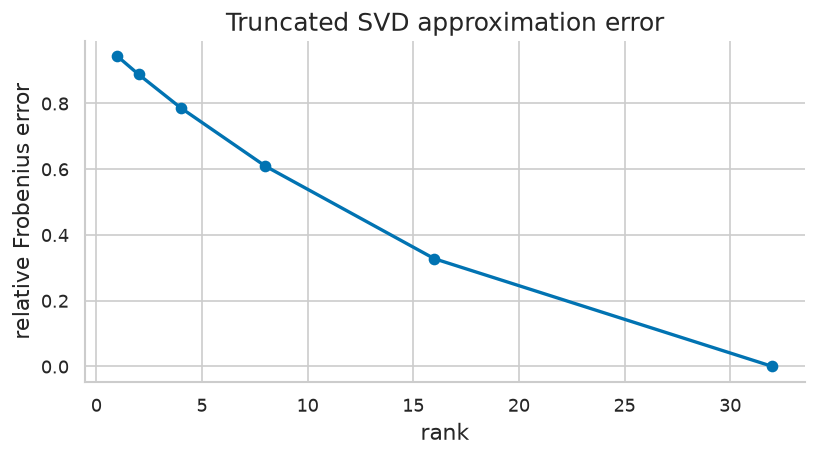

In [5]:
rng = np.random.default_rng(3)
delta = rng.normal(size=(32, 32))
U, S, Vt = np.linalg.svd(delta, full_matrices=False)
errors = []
for r in [1, 2, 4, 8, 16, 32]:
    approx = (U[:, :r] * S[:r]) @ Vt[:r, :]
    rel_error = np.linalg.norm(delta - approx) / np.linalg.norm(delta)
    errors.append(rel_error)
    print(f"rank {r:>2}: relative error {rel_error:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([1, 2, 4, 8, 16, 32], errors, marker="o")
ax.set_title("Truncated SVD approximation error")
ax.set_xlabel("rank")
ax.set_ylabel("relative Frobenius error")
fig.tight_layout()
plt.show()

## 5. LoRA update and merge

In [6]:
d_in, d_out, r, alpha = 6, 5, 2, 8
W = np.random.normal(size=(d_out, d_in))
A = np.random.normal(scale=0.02, size=(r, d_in))
B = np.random.normal(scale=0.02, size=(d_out, r))
delta_W = (alpha / r) * (B @ A)
W_merged = W + delta_W
x = np.random.normal(size=(d_in,))
before = W @ x
after_adapter = W @ x + delta_W @ x
after_merged = W_merged @ x
print("delta_W shape:", delta_W.shape)
print("merge error:", np.max(np.abs(after_adapter - after_merged)))

delta_W shape: (5, 6)
merge error: 2.220446049250313e-16


## 6. Adapter bottleneck count

In [7]:
d_model = 4096
bottleneck = 64
layers = 32
per_layer = d_model * bottleneck + bottleneck * d_model
total = layers * per_layer
print("adapter params per layer:", per_layer)
print("adapter params total:", total)

adapter params per layer: 524288
adapter params total: 16777216


## 7. Prefix-tuning parameter count

In [8]:
layers = 32
prefix_len = 16
heads = 32
head_dim = 128
kv = 2
prefix_params = layers * prefix_len * heads * head_dim * kv
print("prefix parameters:", prefix_params)
print("million:", prefix_params / 1e6)

prefix parameters: 4194304
million: 4.194304


## 8. Memory effect of PEFT

In [9]:
base_params = 7e9
lora_params = 40e6
adam_bytes_per_trainable = 12
base_optimizer_gb = base_params * adam_bytes_per_trainable / 1e9
lora_optimizer_gb = lora_params * adam_bytes_per_trainable / 1e9
print("full Adam state GB:", base_optimizer_gb)
print("LoRA Adam state GB:", lora_optimizer_gb)
print("reduction factor:", base_optimizer_gb / lora_optimizer_gb)

full Adam state GB: 84.0
LoRA Adam state GB: 0.48
reduction factor: 175.0


## 9. DPO loss for one preference pair

In [10]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

beta = 0.1
logp_theta_chosen = -12.0
logp_theta_rejected = -15.0
logp_ref_chosen = -13.0
logp_ref_rejected = -14.0
margin = (logp_theta_chosen - logp_theta_rejected) - (logp_ref_chosen - logp_ref_rejected)
loss = -np.log(sigmoid(beta * margin))
print("preference margin:", margin)
print("DPO loss:", loss)

preference margin: 2.0
DPO loss: 0.5981388693815918


## 10. KL penalty intuition

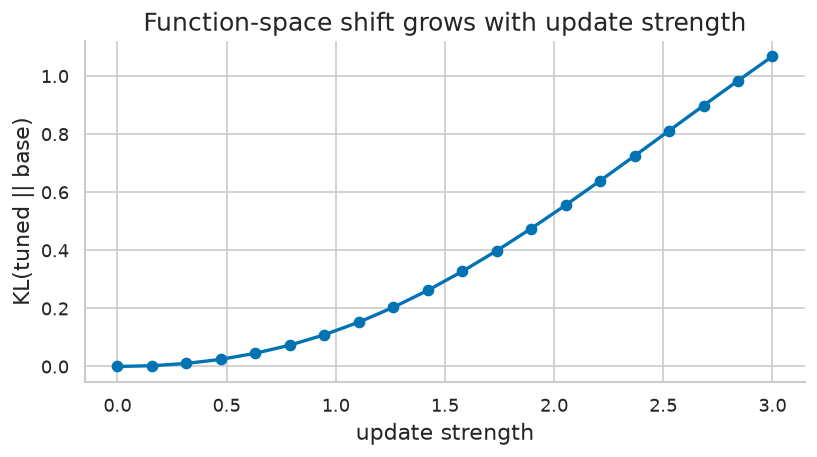

final KL: 1.0676230894376795


In [11]:
def softmax(z):
    z = np.asarray(z, dtype=float)
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

base_logits = np.array([2.0, 1.0, 0.0])
direction = np.array([-0.5, 0.2, 0.8])
strengths = np.linspace(0, 3, 20)
kls = []
for s in strengths:
    p0 = softmax(base_logits)
    p1 = softmax(base_logits + s * direction)
    kls.append(np.sum(p1 * (np.log(p1 + 1e-12) - np.log(p0 + 1e-12))))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(strengths, kls, marker="o")
ax.set_title("Function-space shift grows with update strength")
ax.set_xlabel("update strength")
ax.set_ylabel("KL(tuned || base)")
fig.tight_layout()
plt.show()
print("final KL:", kls[-1])

## 11. Layer-wise learning-rate decay

In [12]:
layers = np.arange(1, 13)
eta_top = 2e-5
gamma = 0.85
lrs = eta_top * gamma ** (layers.max() - layers)
for layer, lr in zip(layers, lrs):
    print(f"layer {layer:>2}: lr={lr:.8f}")

layer  1: lr=0.00000335
layer  2: lr=0.00000394
layer  3: lr=0.00000463
layer  4: lr=0.00000545
layer  5: lr=0.00000641
layer  6: lr=0.00000754
layer  7: lr=0.00000887
layer  8: lr=0.00001044
layer  9: lr=0.00001228
layer 10: lr=0.00001445
layer 11: lr=0.00001700
layer 12: lr=0.00002000


## 12. Task quality versus retention

In [13]:
methods = ["base", "prompt", "lora-r8", "lora-r32", "full"]
task = np.array([0.45, 0.58, 0.72, 0.78, 0.82])
retain = np.array([0.90, 0.89, 0.86, 0.82, 0.70])
score = 0.7 * task + 0.3 * retain
for m, t, r, s in zip(methods, task, retain, score):
    print(f"{m:>8s}: task={t:.2f} retain={r:.2f} combined={s:.3f}")

    base: task=0.45 retain=0.90 combined=0.585
  prompt: task=0.58 retain=0.89 combined=0.673
 lora-r8: task=0.72 retain=0.86 combined=0.762
lora-r32: task=0.78 retain=0.82 combined=0.792
    full: task=0.82 retain=0.70 combined=0.784


## 13. Trainable-parameter audit

In [14]:
params = {
    "base.embed": False,
    "base.block1.q_proj": False,
    "base.block1.q_proj.lora_A": True,
    "base.block1.q_proj.lora_B": True,
    "lm_head": False,
}
for name, trainable in params.items():
    print(f"{name:30s} trainable={trainable}")
print("trainable tensors:", sum(params.values()))

base.embed                     trainable=False
base.block1.q_proj             trainable=False
base.block1.q_proj.lora_A      trainable=True
base.block1.q_proj.lora_B      trainable=True
lm_head                        trainable=False
trainable tensors: 2


## 14. Final fine-tuning checklist

In [15]:
checks = [
    "prompt and answer masks match the objective",
    "only intended tensors require gradients",
    "trainable parameter count matches expectation",
    "base, prompt-only, and tuned model are compared",
    "retention and task quality are both measured",
    "adapter can be disabled or merged for an ablation",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. prompt and answer masks match the objective
2. only intended tensors require gradients
3. trainable parameter count matches expectation
4. base, prompt-only, and tuned model are compared
5. retention and task quality are both measured
6. adapter can be disabled or merged for an ablation


## New demo: LoRA parameter counting (new, notes 11.1/18.1)

In [16]:
for d in [1024,4096,8192]:
    for r in [4,16,64]:
        print(f"d={d}, r={r}: LoRA {r*2*d:,} vs full {d*d:,} ({100*r*2*d/(d*d):.2f}%)")
ok=16*2*4096==131072
print(f"{'PASS' if ok else 'FAIL'} - rank-16 LoRA on 4096x4096 has 131072 parameters")

d=1024, r=4: LoRA 8,192 vs full 1,048,576 (0.78%)
d=1024, r=16: LoRA 32,768 vs full 1,048,576 (3.12%)
d=1024, r=64: LoRA 131,072 vs full 1,048,576 (12.50%)
d=4096, r=4: LoRA 32,768 vs full 16,777,216 (0.20%)
d=4096, r=16: LoRA 131,072 vs full 16,777,216 (0.78%)
d=4096, r=64: LoRA 524,288 vs full 16,777,216 (3.12%)
d=8192, r=4: LoRA 65,536 vs full 67,108,864 (0.10%)
d=8192, r=16: LoRA 262,144 vs full 67,108,864 (0.39%)
d=8192, r=64: LoRA 1,048,576 vs full 67,108,864 (1.56%)
PASS - rank-16 LoRA on 4096x4096 has 131072 parameters


## New demo: Merged LoRA equals unmerged forward (new, notes 19.2)

In [17]:
rng=np.random.default_rng(42); W0=rng.normal(size=(4,4)); A=rng.normal(size=(2,4)); B=np.zeros((4,2)); B[:,0]=[1,0,2,-1]; alpha_over_r=0.5; x=rng.normal(size=4)
unmerged=W0@x+alpha_over_r*(B@(A@x)); merged=(W0+alpha_over_r*B@A)@x
print("max difference:", float(np.abs(unmerged-merged).max()))
print(f"{'PASS' if np.allclose(unmerged,merged) else 'FAIL'} - merged weight reproduces adapted function")

max difference: 1.1102230246251565e-16
PASS - merged weight reproduces adapted function


## New demo: DPO loss versus policy movement (new, notes 13.2/18.2)

In [18]:
import math
def dpo(delta,beta): return -math.log(1/(1+math.exp(-beta*delta)))
for beta in [0.1,1.0]:
    vals=[round(dpo(d,beta),3) for d in [0,0.5,1,2,5]]; print(f"beta={beta}: losses at Delta=0,0.5,1,2,5 -> {vals}")
ok=abs(dpo(0,0.1)-math.log(2))<1e-9
print(f"{'PASS' if ok else 'FAIL'} - zero movement gives chance loss ln2")

beta=0.1: losses at Delta=0,0.5,1,2,5 -> [0.693, 0.668, 0.644, 0.598, 0.474]
beta=1.0: losses at Delta=0,0.5,1,2,5 -> [0.693, 0.474, 0.313, 0.127, 0.007]
PASS - zero movement gives chance loss ln2


## New demo: Answer-only loss masks the prompt (new, Problem 4)

In [19]:
nll=np.array([0.1,0.2,0.1,1.0,1.5]); mask=np.array([0,0,0,1,1])
ans=float((nll*mask).sum()/mask.sum()); full=float(nll.mean())
print(f"answer-only loss={ans:.3f}, full-sequence mean={full:.3f}")
print(f"{'PASS' if abs(ans-1.25)<1e-12 and full<ans else 'FAIL'} - masked loss scores only answer tokens")

answer-only loss=1.250, full-sequence mean=0.580
PASS - masked loss scores only answer tokens


## New demo: Label smoothing target for SFT (new, notes 2.4/15 of Ch15-05)

In [20]:
eps,V=0.1,5; y=np.zeros(V); y[2]=1; ys=(1-eps)*y+eps/V
print("smoothed target:", np.round(ys,3), "sum:", float(ys.sum()))
print(f"{'PASS' if abs(ys.sum()-1)<1e-12 and abs(ys[2]-0.92)<1e-12 else 'FAIL'} - smoothed target sums to one")

smoothed target: [0.02 0.02 0.92 0.02 0.02] sum: 1.0
PASS - smoothed target sums to one


## New demo: EWC quadratic penalty (new, notes 14.1/Problem 8)

In [21]:
F=np.array([100.0,0.01]); move=np.array([0.05,0.05]); lam=1.0
pen=float(lam/2*np.sum(F*move**2)); print(f"EWC penalty={pen:.6f} (dominated by the high-Fisher coordinate)")
print(f"{'PASS' if abs(pen-(0.125+0.0000125))<1e-9 else 'FAIL'} - Fisher prices movement per coordinate")

EWC penalty=0.125013 (dominated by the high-Fisher coordinate)
PASS - Fisher prices movement per coordinate


## New demo: Task-vector addition and negation (new, notes 15.2)

In [22]:
base=np.array([1.0,2.0,3.0]); ft=np.array([1.5,1.5,3.5]); tau=ft-base
print("task vector:",tau,"base+tau:",base+tau,"base-tau:",base-tau)
print(f"{'PASS' if np.allclose(base+tau,ft) else 'FAIL'} - adding the task vector recovers the fine-tune")

task vector: [ 0.5 -0.5  0.5] base+tau: [1.5 1.5 3.5] base-tau: [0.5 2.5 2.5]
PASS - adding the task vector recovers the fine-tune


## New demo: Win-rate confidence interval (new, notes 29.1)

In [23]:
import math
for n,q in [(100,0.52),(2500,0.52)]:
    se=math.sqrt(q*(1-q)/n); print(f"n={n}: win rate {q} +- {1.96*se:.3f}")
ok=math.sqrt(0.52*0.48/2500)<0.011
print(f"{'PASS' if ok else 'FAIL'} - 2500 prompts make a 52% win rate distinguishable from chance")

n=100: win rate 0.52 +- 0.098
n=2500: win rate 0.52 +- 0.020
PASS - 2500 prompts make a 52% win rate distinguishable from chance


## New demo: QLoRA three-term memory accounting (new, notes 16)

In [24]:
params=65e9; weights_4bit=params*0.5/1e9; adapter_gb=0.3; act_gb=8.0
print(f"4-bit base={weights_4bit:.1f} GB, adapters+optimizer~{adapter_gb} GB, activations (example)={act_gb} GB, total~{weights_4bit+adapter_gb+act_gb:.1f} GB")
print(f"{'PASS' if abs(weights_4bit-32.5)<0.1 else 'FAIL'} - 65B at 4 bits is 32.5 GB before activations")

4-bit base=32.5 GB, adapters+optimizer~0.3 GB, activations (example)=8.0 GB, total~40.8 GB
PASS - 65B at 4 bits is 32.5 GB before activations


## New demo: LoRA scaling alpha/r held constant across ranks (new, notes 39)

In [25]:
for r in [4,16,64]:
    alpha=2*r; print(f"r={r}, alpha={alpha}, alpha/r={alpha/r:.1f}")
print(f"{'PASS' if all((2*r)/r==2.0 for r in [4,16,64]) else 'FAIL'} - alpha=2r holds update scale constant")

r=4, alpha=8, alpha/r=2.0
r=16, alpha=32, alpha/r=2.0
r=64, alpha=128, alpha/r=2.0
PASS - alpha=2r holds update scale constant


## New demo: Gradient direction of DPO at zero movement (new, notes 13.2)

In [26]:
beta=0.1; delta=0.0
# derivative of -log sigmoid(beta*delta) wrt delta is -beta*sigmoid(-beta*delta)
grad=-beta*(1/(1+np.exp(beta*delta)))
print(f"d loss/d Delta at 0 = {grad:.4f}")
print(f"{'PASS' if abs(grad-(-0.05))<1e-9 else 'FAIL'} - DPO gradient at zero movement is -beta/2")

d loss/d Delta at 0 = -0.0500
PASS - DPO gradient at zero movement is -beta/2
